<center><h1>Sun_Yizhi_HW4</h1></center>
<br>
<br>

Name: Yizhi Sun
<br>
Github Username: yizhisun515
<br>
USC ID: 6129500198

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os
import glob
import numpy as np
import pandas as pd

Get the AReM Data Set

In [2]:
data_path = "../data/AReM"

activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

total_datasets = 0

for activity in activities:
    files = glob.glob(os.path.join(data_path, activity, "*.csv"))
    print(f"{activity}: {len(files)} files")
    total_datasets += len(files)

print(f"\nTotal datasets: {total_datasets}")

bending1: 7 files
bending2: 6 files
cycling: 15 files
lying: 15 files
sitting: 15 files
standing: 15 files
walking: 15 files

Total datasets: 88


### (b) Splitting Data

In [3]:
# Split datasets into training and test sets
train_files = []
test_files = []

for activity in activities:
    files = sorted(
        glob.glob(os.path.join(data_path, activity, "*.csv"))
    )

    for file in files:
        filename = os.path.basename(file)
        dataset_num = int(filename.replace("dataset", "").replace(".csv", ""))

        if activity in ["bending1", "bending2"]:
            if dataset_num <= 2:
                test_files.append((activity, file))
            else:
                train_files.append((activity, file))
        else:
            if dataset_num <= 3:
                test_files.append((activity, file))
            else:
                train_files.append((activity, file))

print(f"Training instances: {len(train_files)}")
print(f"Test instances: {len(test_files)}")
print(f"Total instances: {len(train_files) + len(test_files)}")

Training instances: 69
Test instances: 19
Total instances: 88


### (c) Feature Extraction

In [4]:
# Read and clean AReM data
def read_arem(file):
    with open(file, "r", encoding="utf-8-sig") as f:
        lines = f.readlines()[5:]

    rows = []

    for line in lines:
        line = line.strip().rstrip(",")

        if not line:
            continue

        values = line.split(",") if "," in line else line.split()

        if len(values) != 7:
            raise ValueError(f"Invalid data format in {file}")

        rows.append([float(v) for v in values[1:]])

    return pd.DataFrame(rows)


# Extract seven time-domain features
def extract_features(file):
    df = read_arem(file)
    features = {}

    for i, col in enumerate(df.columns, start=1):
        x = df[col]

        features[f"min{i}"] = x.min()
        features[f"max{i}"] = x.max()
        features[f"mean{i}"] = x.mean()
        features[f"median{i}"] = x.median()
        features[f"std{i}"] = x.std()
        features[f"q1_{i}"] = x.quantile(0.25)
        features[f"q3_{i}"] = x.quantile(0.75)

    return features


# Create training and test feature matrices
X_train = pd.DataFrame(
    [extract_features(file) for activity, file in train_files]
)

X_test = pd.DataFrame(
    [extract_features(file) for activity, file in test_files]
)


# Binary labels: bending = 1, other activities = 0
y_train = np.array([
    int(activity in ["bending1", "bending2"])
    for activity, file in train_files
])

y_test = np.array([
    int(activity in ["bending1", "bending2"])
    for activity, file in test_files
])


# Verify extracted features
print("Training feature matrix:", X_train.shape)
print("Test feature matrix:", X_test.shape)

print("\nMissing values in training:", X_train.isna().sum().sum())
print("Missing values in test:", X_test.isna().sum().sum())

display(X_train.head())

Training feature matrix: (69, 42)
Test feature matrix: (19, 42)

Missing values in training: 0
Missing values in test: 0


,min1,max1,mean1,median1,std1,q1_1,q3_1,min2,max2,mean2,...,std5,q1_5,q3_5,min6,max6,mean6,median6,std6,q1_6,q3_6
0,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94
1,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00
2,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50
3,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87
4,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

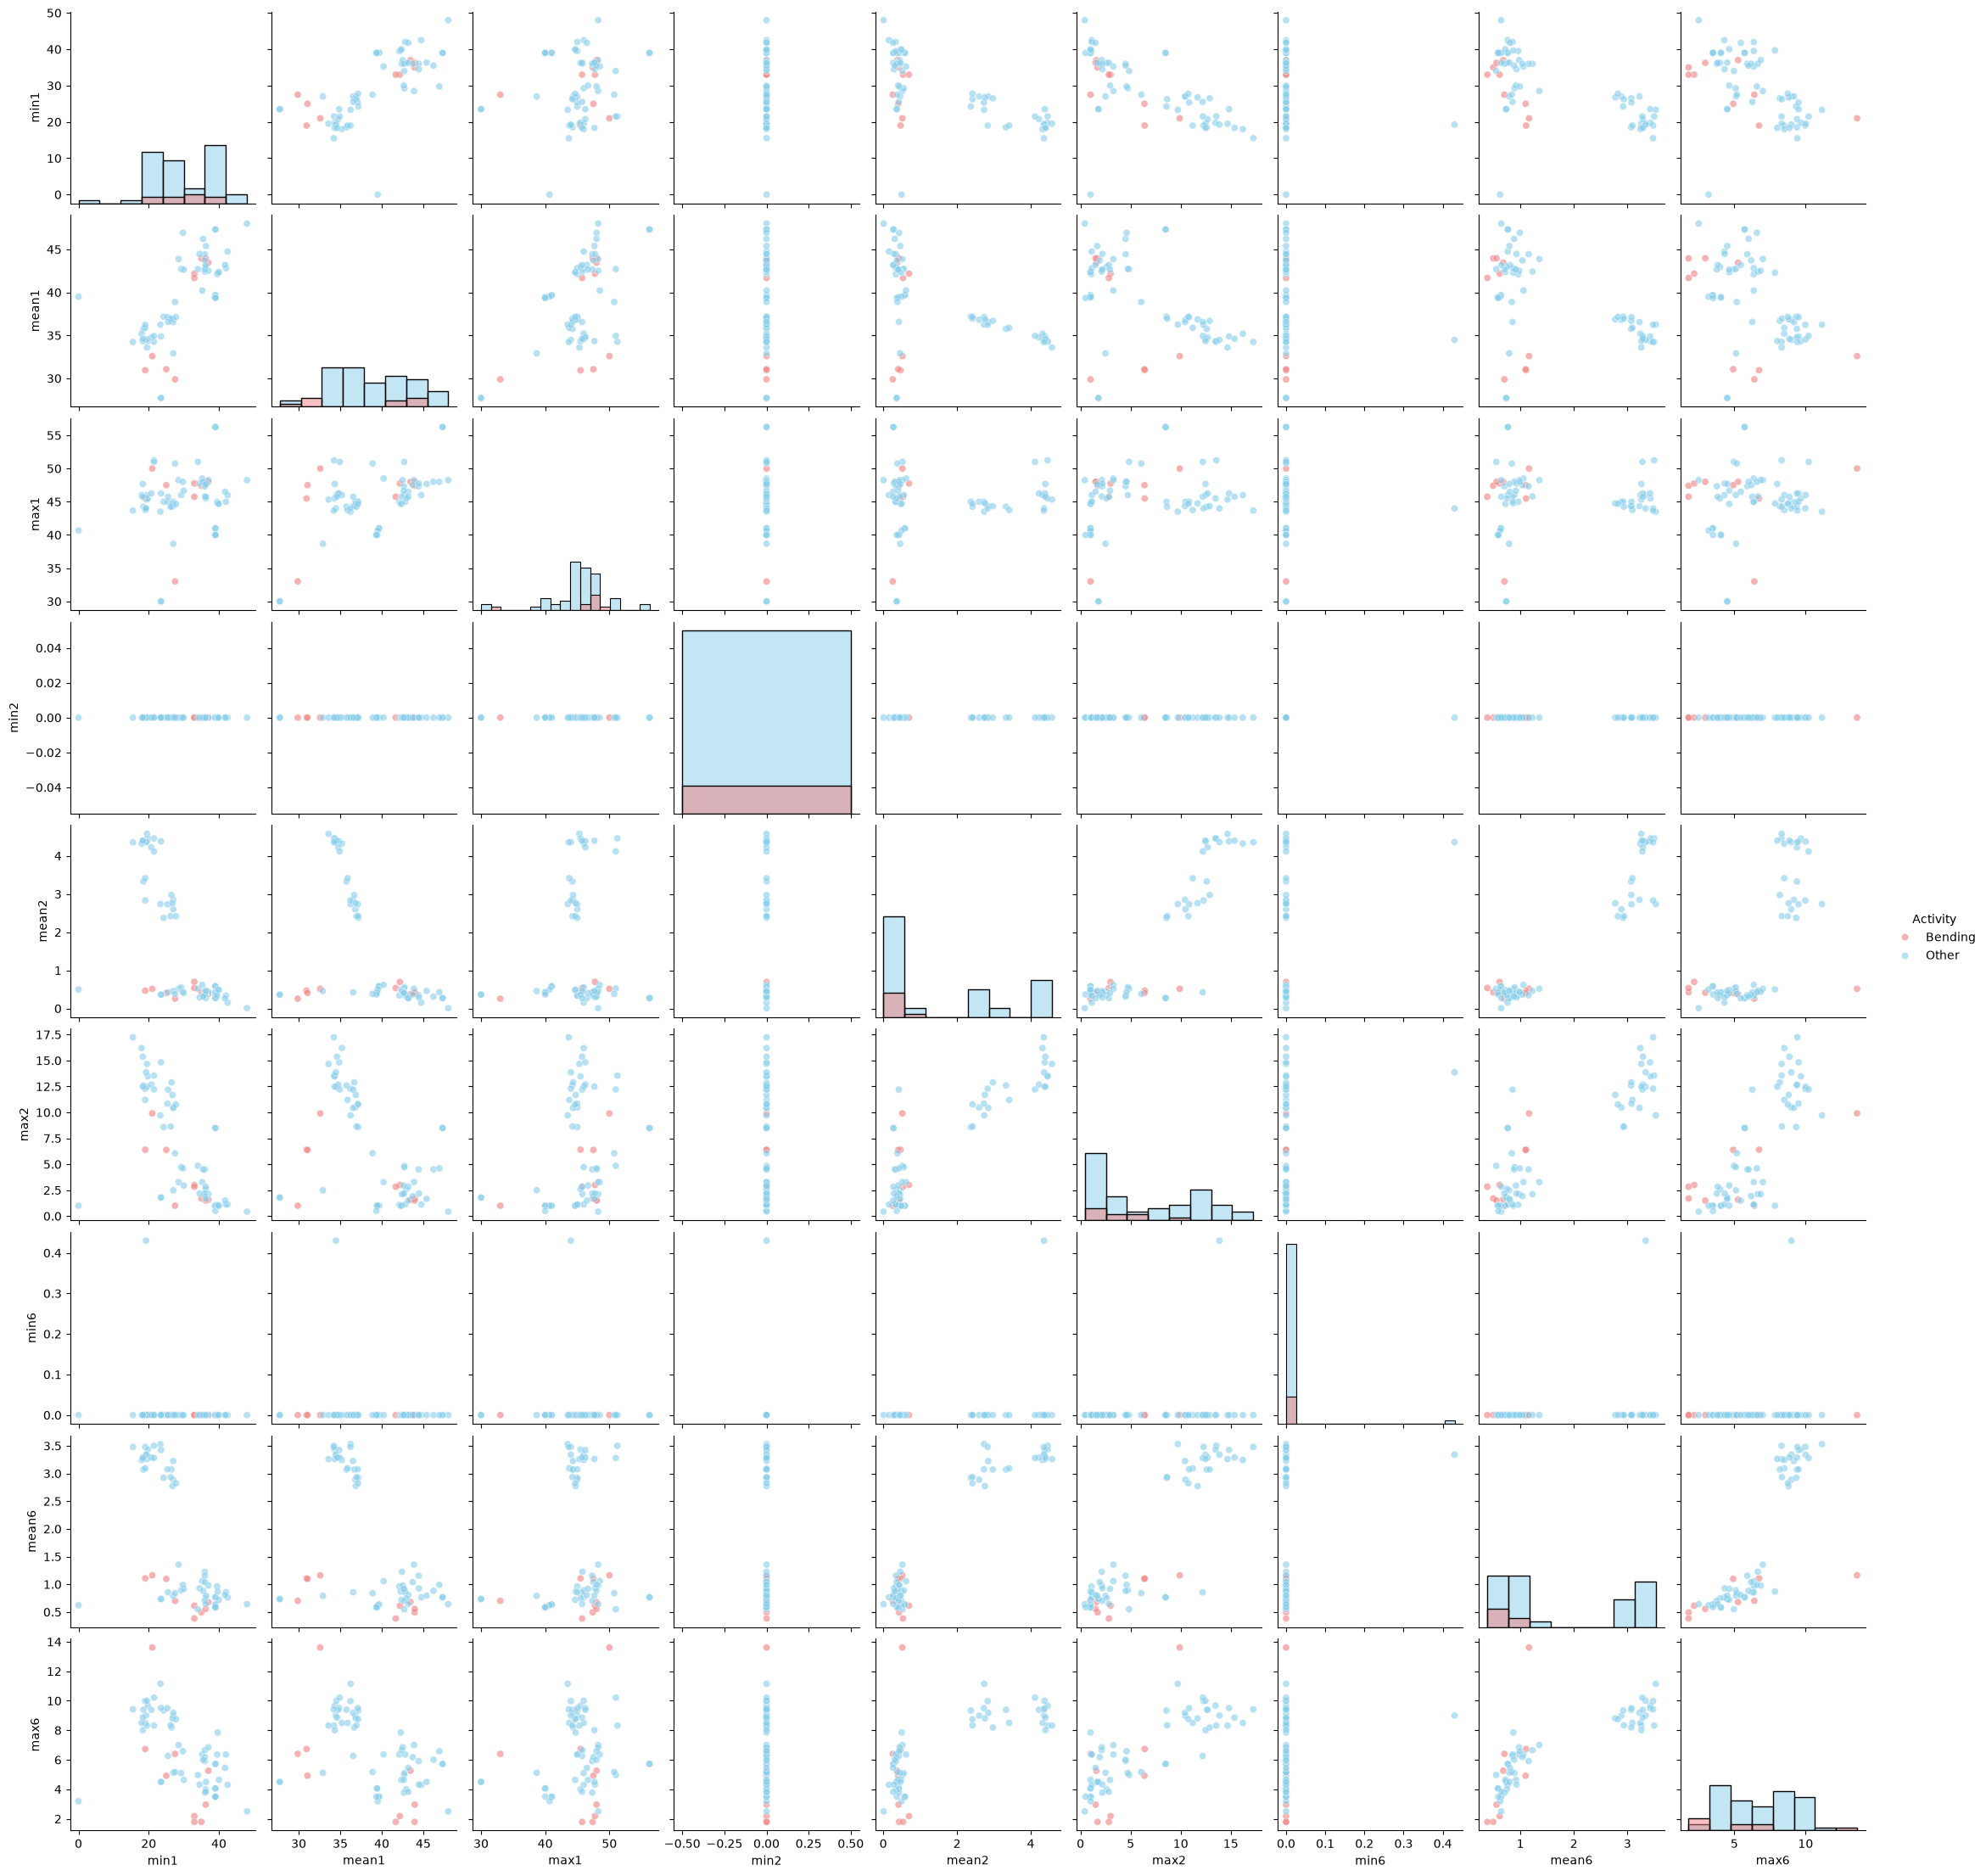

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select min, mean, and max from time series 1, 2, and 6
selected_features = [
    f"{feature}{i}"
    for i in [1, 2, 6]
    for feature in ["min", "mean", "max"]
]

plot_data = X_train[selected_features].copy()

plot_data["Activity"] = np.where(
    y_train == 1, "Bending", "Other"
)

# Create scatter plot matrix
sns.pairplot(
    plot_data,
    hue="Activity",
    vars=selected_features,
    palette={"Bending": "lightcoral", "Other": "skyblue"},
    diag_kind="hist",
    plot_kws={"alpha": 0.6, "s": 35}
)

plt.show()

#### ii. Splitted Plots

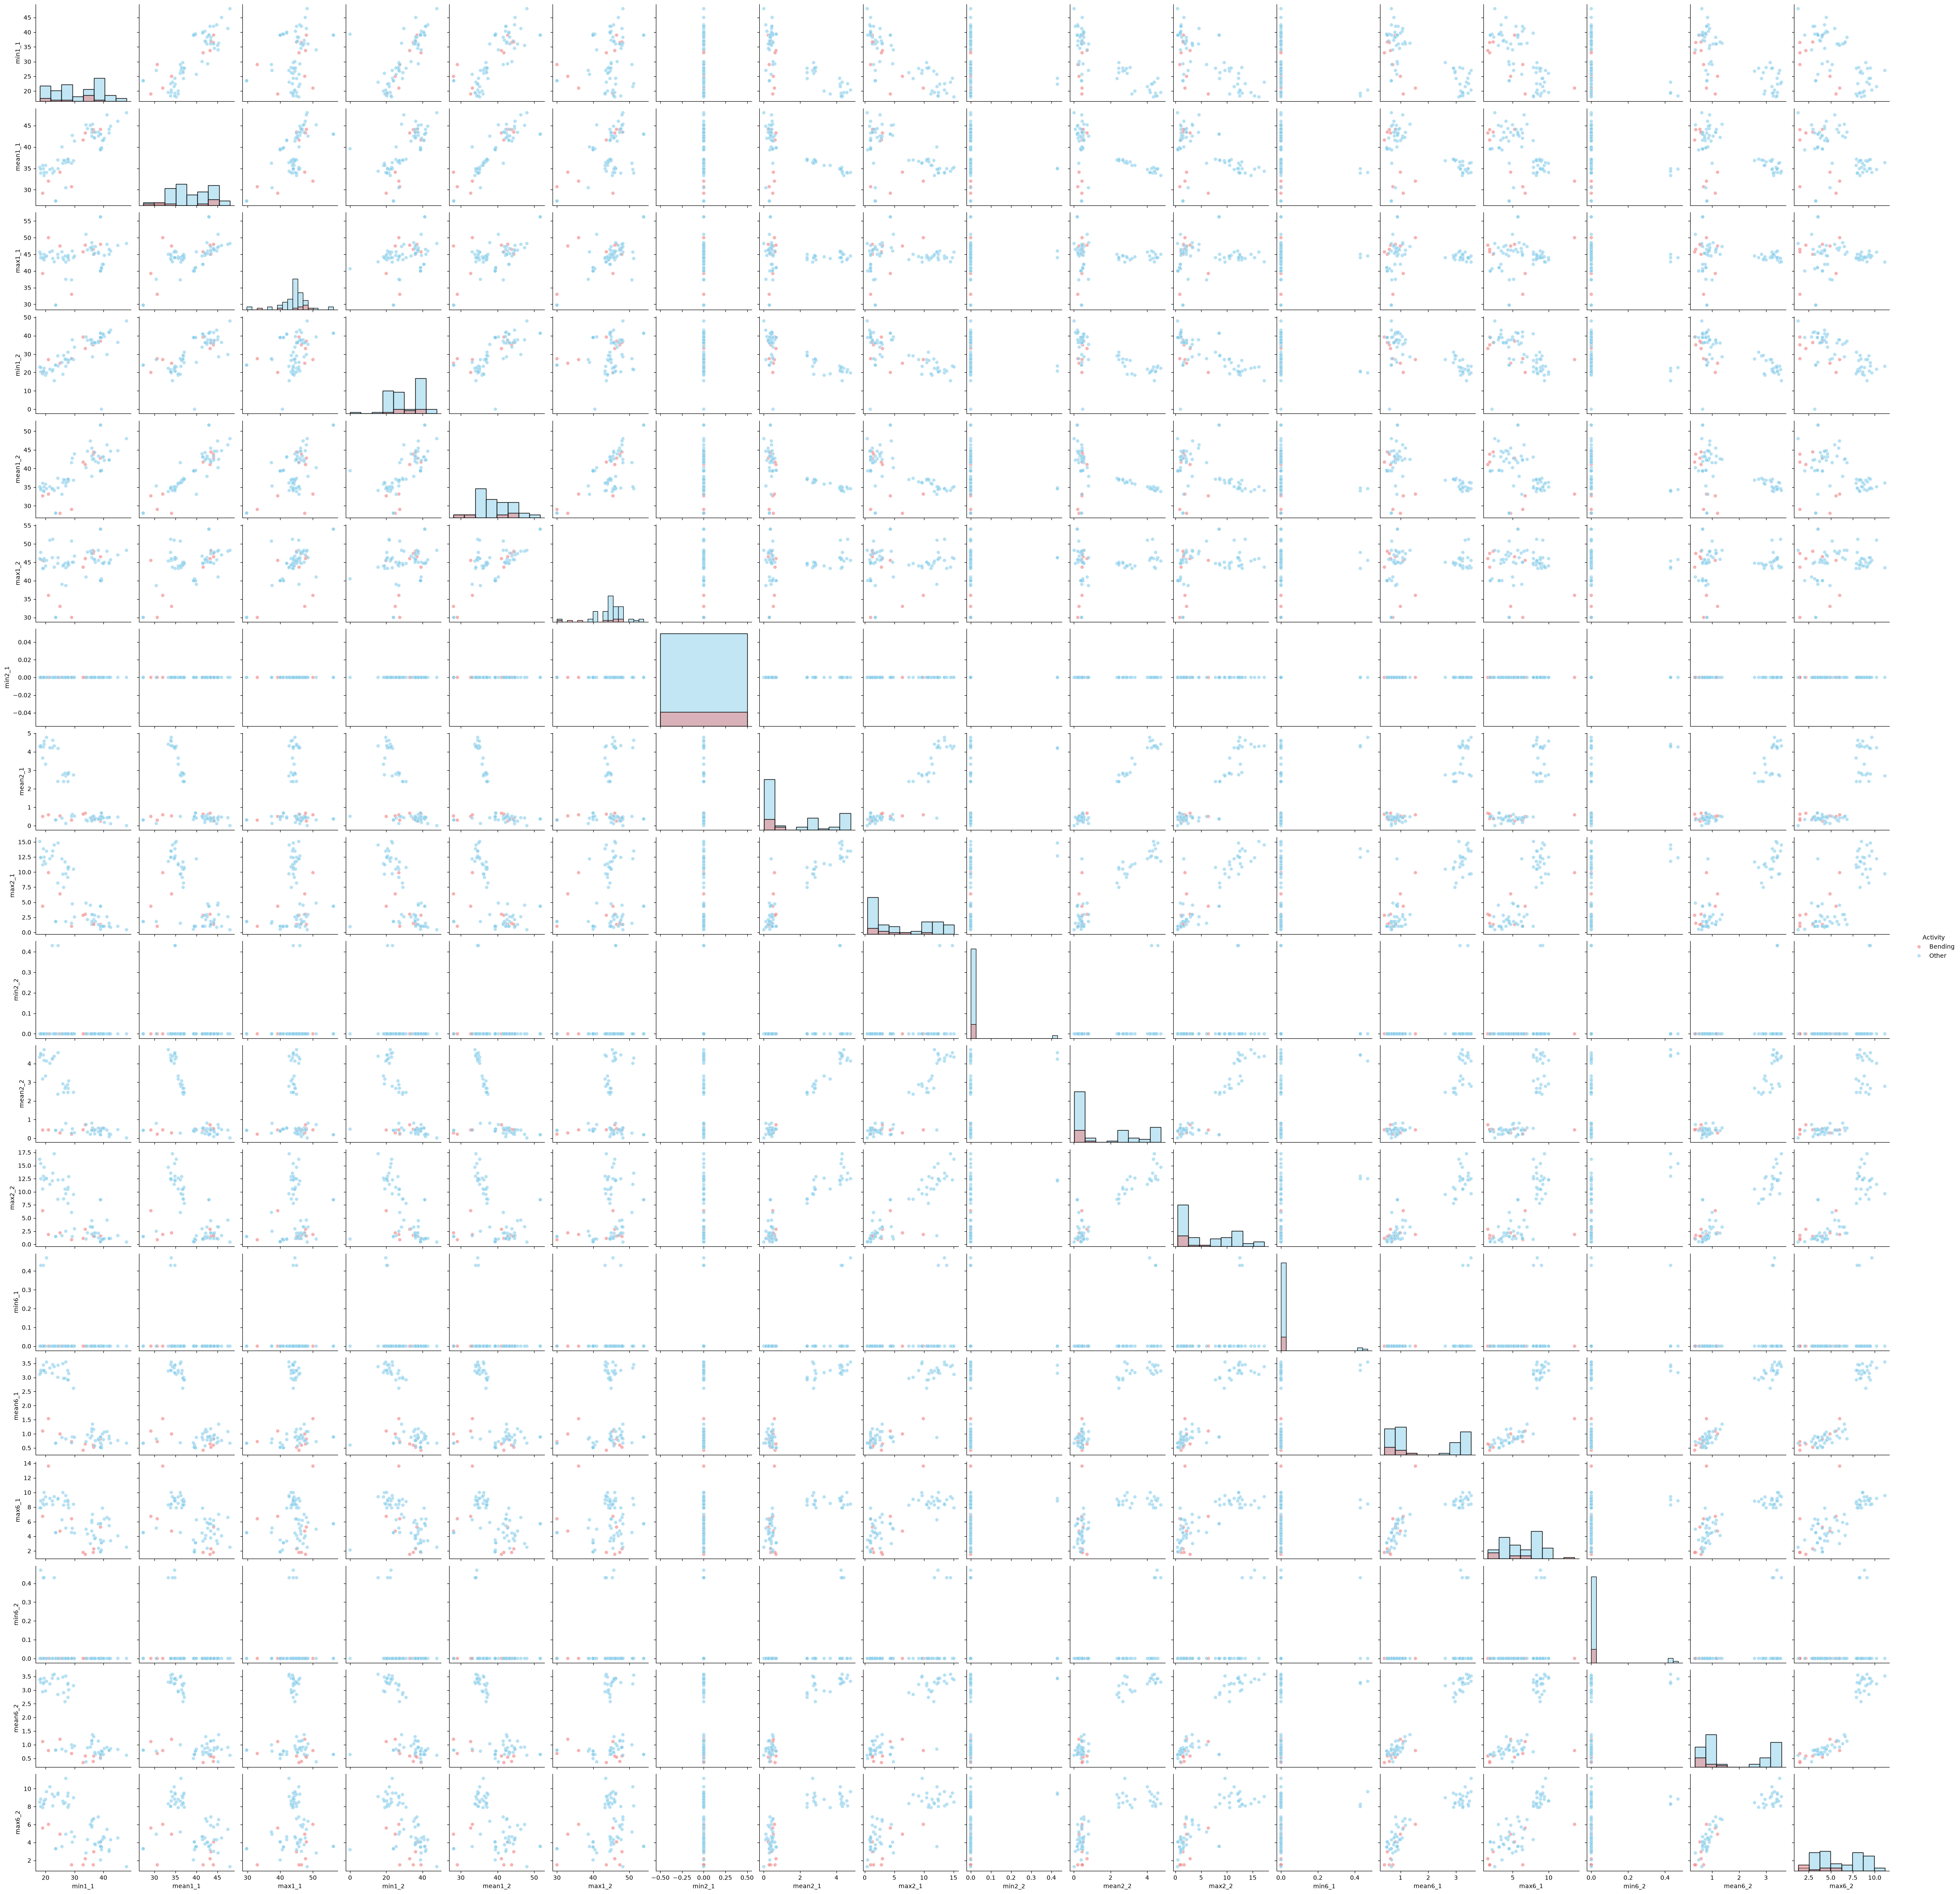

Segmented feature matrix: (69, 18)


In [6]:
# Extract features from two segments of time series 1, 2, and 6
def extract_segment_features(file):
    df = read_arem(file)
    features = {}

    for i in [1, 2, 6]:
        x = df.iloc[:, i - 1].to_numpy()
        segments = np.array_split(x, 2)

        for j, segment in enumerate(segments, start=1):
            features[f"min{i}_{j}"] = np.min(segment)
            features[f"mean{i}_{j}"] = np.mean(segment)
            features[f"max{i}_{j}"] = np.max(segment)

    return features


# Extract features from training instances only
X_train_split = pd.DataFrame(
    [extract_segment_features(file) for activity, file in train_files]
)

plot_data_split = X_train_split.copy()

plot_data_split["Activity"] = np.where(
    y_train == 1, "Bending", "Other"
)

# Plot scatter matrix
sns.pairplot(
    plot_data_split,
    hue="Activity",
    vars=X_train_split.columns,
    palette={"Bending": "lightcoral", "Other": "skyblue"},
    diag_kind="hist",
    plot_kws={"alpha": 0.6, "s": 35}
)

plt.show()

print("Segmented feature matrix:", X_train_split.shape)

Splitting each time series into two segments provides more detailed
information about temporal variation. Compared with the original
scatter plots, some feature combinations show slightly better
separation between bending and other activities, particularly
features from time series 2. However, substantial overlap remains
between the two classes. Therefore, splitting the time series does
not appear to produce a dramatic improvement in class separation.

#### iii. Time Series Segments

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Extract features for l segments
def extract_l_features(file, l):
    df = read_arem(file)
    features = {}

    for i in range(6):
        segments = np.array_split(df.iloc[:, i].to_numpy(), l)

        for j, segment in enumerate(segments, start=1):
            features[f"min{i+1}_{j}"] = np.min(segment)
            features[f"max{i+1}_{j}"] = np.max(segment)
            features[f"mean{i+1}_{j}"] = np.mean(segment)
            features[f"median{i+1}_{j}"] = np.median(segment)
            features[f"std{i+1}_{j}"] = np.std(segment, ddof=1)
            features[f"q1_{i+1}_{j}"] = np.percentile(segment, 25)
            features[f"q3_{i+1}_{j}"] = np.percentile(segment, 75)

    return features


# Set up stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
feature_sets = {}

# Search over segment counts and selected feature counts
for l in range(1, 21):

    X_l = pd.DataFrame([
        extract_l_features(file, l)
        for activity, file in train_files
    ])

    feature_sets[l] = X_l

    for p in [5, 10, 20, 40]:

        model = LogisticRegression(
            C=1e4,
            max_iter=1000,
            solver="liblinear"
        )

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("rfe", RFE(
                estimator=model,
                n_features_to_select=p,
                step=0.2
            )),
            ("classifier", model)
        ])

        scores = cross_val_score(
            pipeline,
            X_l,
            y_train,
            cv=cv,
            scoring="accuracy"
        )

        results.append({
            "l": l,
            "p": p,
            "CV Accuracy": scores.mean()
        })


# Display best combinations
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "CV Accuracy",
    ascending=False
).reset_index(drop=True)

display(results_df.head(10))

best_l = int(results_df.loc[0, "l"])
best_p = int(results_df.loc[0, "p"])
best_score = results_df.loc[0, "CV Accuracy"]

print(f"Best l: {best_l}")
print(f"Best p: {best_p}")
print(f"Best CV Accuracy: {best_score:.4f}")

,l,p,CV Accuracy
0,10,20,0.985714
1,4,5,0.985714
2,1,10,0.985714
3,1,20,0.971429
4,1,40,0.971429
5,19,10,0.971429
6,17,10,0.957143
7,6,10,0.957143
8,6,5,0.957143
9,10,10,0.957143


Best l: 10
Best p: 20
Best CV Accuracy: 0.9857


In [8]:
# Refine the number of selected features for promising segment counts
refined_results = []

for l in [1, 4, 10]:

    X_l = feature_sets[l]

    for p in range(1, 31):

        model = LogisticRegression(
            C=1e4,
            max_iter=1000,
            solver="liblinear"
        )

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("rfe", RFE(
                estimator=model,
                n_features_to_select=p,
                step=0.2
            )),
            ("classifier", model)
        ])

        scores = cross_val_score(
            pipeline,
            X_l,
            y_train,
            cv=cv,
            scoring="accuracy"
        )

        refined_results.append({
            "l": l,
            "p": p,
            "CV Accuracy": scores.mean()
        })


refined_df = pd.DataFrame(refined_results)

refined_df = refined_df.sort_values(
    ["CV Accuracy", "p", "l"],
    ascending=[False, True, True]
).reset_index(drop=True)

display(refined_df.head(15))

best_l = int(refined_df.loc[0, "l"])
best_p = int(refined_df.loc[0, "p"])
best_score = refined_df.loc[0, "CV Accuracy"]

print(f"Selected l: {best_l}")
print(f"Selected p: {best_p}")
print(f"CV Accuracy: {best_score:.4f}")

,l,p,CV Accuracy
0,4,5,0.985714
1,1,10,0.985714
2,1,15,0.985714
3,10,20,0.985714
4,10,21,0.985714
5,1,28,0.985714
6,1,4,0.971429
7,1,7,0.971429
8,1,8,0.971429
9,1,9,0.971429


Selected l: 4
Selected p: 5
CV Accuracy: 0.9857


**Cross-Validation and Feature Selection**

Stratified 5-fold cross-validation was used to select the number
of segments (l) and the number of retained features (p).

The correct approach performs standardization, recursive feature
elimination (RFE), and model fitting separately within each
training fold. Performing feature selection on the entire training
dataset before cross-validation would introduce data leakage,
leading to overly optimistic performance estimates.

The initial grid search evaluated l = 1–20 and p = {5, 10, 20, 40}.
A refined search was then conducted for l = {1, 4, 10} and p = 1–30.

Multiple combinations achieved the highest CV accuracy of 98.57%.
The combination (l = 4, p = 5) was selected because it achieved
this accuracy using the fewest retained features among the
evaluated combinations.

#### iv. Confusion Matrix

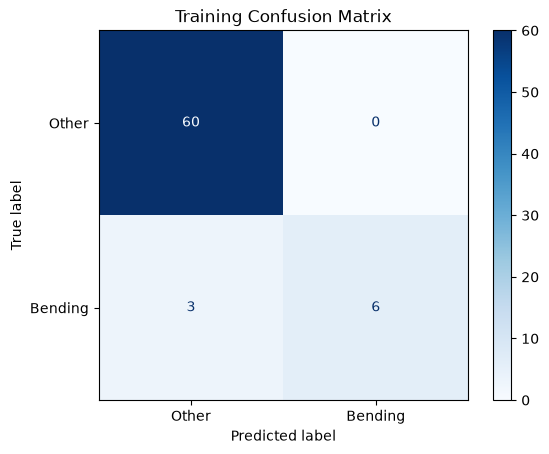

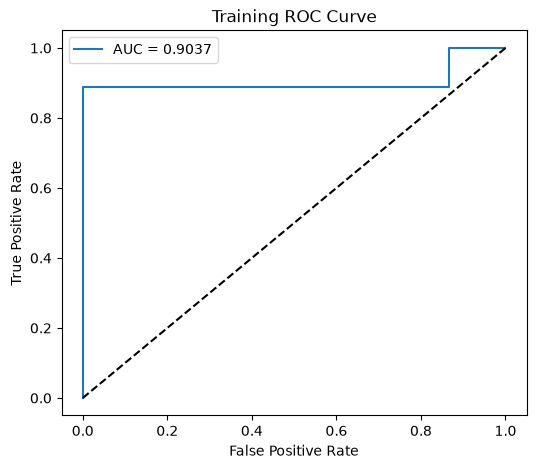

Training Accuracy: 0.9565
Training AUC: 0.9037

Selected Features:
['std1_4', 'max2_1', 'q1_3_3', 'min5_4', 'max6_2']


,Feature,Coefficient
0,std1_4,0.085325
1,max2_1,-0.838446
2,q1_3_3,1.667578
3,min5_4,2.872143
4,max6_2,-1.125646


,Feature,Coefficient,P-value
0,Intercept,-3.153637,0.000109
1,std1_4,0.085276,0.897142
2,max2_1,-0.838457,0.424150
3,q1_3_3,1.668142,0.078586
4,min5_4,2.872947,0.018050
5,max6_2,-1.125989,0.254019


In [9]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)
import statsmodels.api as sm
import warnings

# Fit the final logistic regression model
final_model = LogisticRegression(
    C=1e4,
    max_iter=1000,
    solver="liblinear"
)

final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=final_model,
        n_features_to_select=best_p,
        step=0.2
    )),
    ("classifier", final_model)
])

X_best = feature_sets[best_l]
final_pipeline.fit(X_best, y_train)

# Training predictions
y_pred_train = final_pipeline.predict(X_best)
y_prob_train = final_pipeline.predict_proba(X_best)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_train, y_pred_train)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title("Training Confusion Matrix")
plt.show()

# ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_train, y_prob_train)
train_auc = roc_auc_score(y_train, y_prob_train)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {train_auc:.4f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend()
plt.show()

print(f"Training Accuracy: {(y_pred_train == y_train).mean():.4f}")
print(f"Training AUC: {train_auc:.4f}")

# Selected features
selected_mask = final_pipeline.named_steps["rfe"].support_
selected_features = X_best.columns[selected_mask]

print("\nSelected Features:")
print(list(selected_features))

# Logistic regression coefficients
scaler = final_pipeline.named_steps["scaler"]
classifier = final_pipeline.named_steps["classifier"]

coef_table = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": classifier.coef_[0]
})

display(coef_table)

# Estimate p-values using statsmodels
X_scaled = scaler.transform(X_best)
X_selected = X_scaled[:, selected_mask]
X_sm = sm.add_constant(X_selected)

try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        logit_model = sm.Logit(y_train, X_sm).fit(
            disp=False,
            maxiter=100
        )

    pvalue_table = pd.DataFrame({
        "Feature": ["Intercept"] + list(selected_features),
        "Coefficient": logit_model.params,
        "P-value": logit_model.pvalues
    })

    display(pvalue_table)

except (Exception) as e:
    print("Statsmodels estimation failed:", str(e))
    print("Possible complete or quasi-complete separation.")

The logistic regression classifier achieved a training accuracy of
95.65% and an AUC of 0.9037. The confusion matrix shows that all
60 non-bending instances were correctly classified, while 6 out
of 9 bending instances were correctly identified.

Among the five selected features, min5_4 had a p-value below
0.05. However, these p-values should be interpreted cautiously
because the features were selected using RFE.

Although the training accuracy was lower than the selected
cross-validation accuracy (98.57%), the two estimates are based
on different fitting and evaluation procedures.

#### v. Test Classifier

Selected l: 4
Selected p: 5

CV Accuracy: 0.9857
Training Accuracy: 0.9565
Test Accuracy: 0.9474


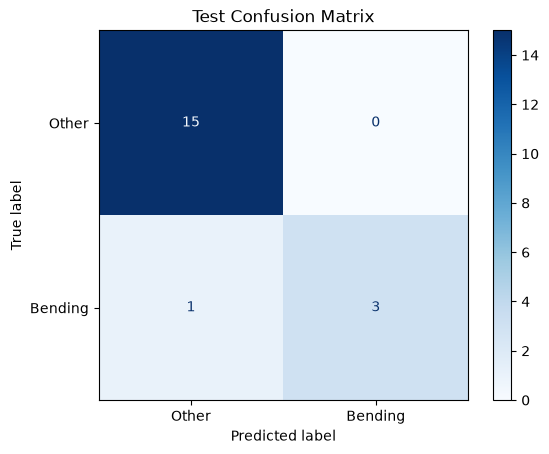


Test Classification Report:
              precision    recall  f1-score   support

       Other       0.94      1.00      0.97        15
     Bending       1.00      0.75      0.86         4

    accuracy                           0.95        19
   macro avg       0.97      0.88      0.91        19
weighted avg       0.95      0.95      0.94        19



In [10]:
from sklearn.metrics import accuracy_score, classification_report

# Extract test features using the selected number of segments
X_test_best = pd.DataFrame([
    extract_l_features(file, best_l)
    for activity, file in test_files
])

# Match the training feature order
X_test_best = X_test_best[X_best.columns]

# Predict using the previously fitted pipeline
y_pred_test = final_pipeline.predict(X_test_best)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"Selected l: {best_l}")
print(f"Selected p: {best_p}")

print(f"\nCV Accuracy: {best_score:.4f}")
print(f"Training Accuracy: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Test confusion matrix
test_cm = confusion_matrix(y_test, y_pred_test)

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title("Test Confusion Matrix")
plt.show()

# Classification report
print("\nTest Classification Report:")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=["Other", "Bending"],
    zero_division=0
))

The classifier achieved a test accuracy of 94.74%, slightly lower
than the cross-validation accuracy of 98.57%.

The confusion matrix shows that all 15 non-bending instances
were correctly classified, while 3 out of 4 bending instances
were correctly identified.

The results suggest good generalization to unseen data.
However, the relatively small test set and lower recall for
bending (75%) indicate that performance should be interpreted
with caution.

#### vi. Separation

The classes do not appear to cause severe instability in the
fitted logistic regression model. The training accuracy was
95.65%, and the model produced finite coefficient estimates
without obvious convergence issues.

However, these results do not completely rule out separation,
as regularization and finite iteration limits may mask numerical
instability. Therefore, the coefficient estimates and p-values
should be interpreted with caution.

#### vii. Imbalance

Case-control class counts:
0    9
1    9
Name: count, dtype: int64

Original intercept: 1.2439
Adjusted intercept: -0.6532


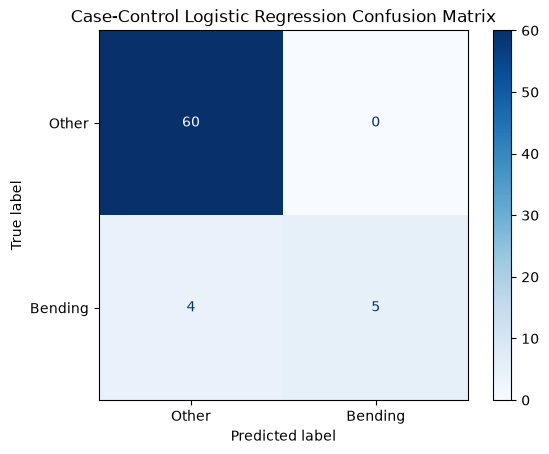

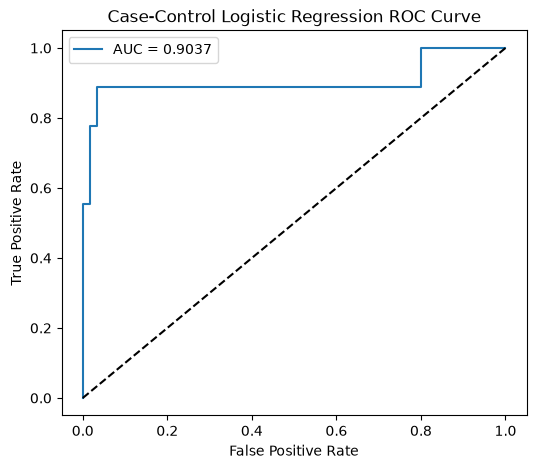

Case-Control Training Accuracy: 0.9420
Case-Control Training AUC: 0.9037
Original Training AUC: 0.9037


In [11]:
from sklearn.utils import resample
from sklearn.metrics import roc_curve, roc_auc_score

# Create a balanced case-control sample
rng = np.random.RandomState(42)

case_idx = np.where(y_train == 1)[0]
control_idx = np.where(y_train == 0)[0]

sampled_controls = rng.choice(
    control_idx,
    size=len(case_idx),
    replace=False
)

sample_idx = np.concatenate([case_idx, sampled_controls])

# Use the five features selected previously
X_selected = X_best.loc[:, selected_features]

X_cc = X_selected.iloc[sample_idx]
y_cc = y_train[sample_idx]

print("Case-control class counts:")
print(pd.Series(y_cc).value_counts().sort_index())

# Fit logistic regression on the balanced sample
cc_scaler = StandardScaler()
X_cc_scaled = cc_scaler.fit_transform(X_cc)

cc_model = LogisticRegression(
    C=1e4,
    max_iter=1000,
    solver="liblinear"
)

cc_model.fit(X_cc_scaled, y_cc)

# Adjust the intercept for the original class proportion
pi = np.mean(y_train)
pi_s = np.mean(y_cc)

intercept_adjustment = (
    np.log(pi / (1 - pi))
    - np.log(pi_s / (1 - pi_s))
)

adjusted_intercept = (
    cc_model.intercept_[0] + intercept_adjustment
)

print(f"\nOriginal intercept: {cc_model.intercept_[0]:.4f}")
print(f"Adjusted intercept: {adjusted_intercept:.4f}")

# Evaluate on the original training distribution
X_all_scaled = cc_scaler.transform(X_selected)

logits = (
    X_all_scaled @ cc_model.coef_[0]
    + adjusted_intercept
)

y_prob_cc = 1 / (1 + np.exp(-logits))
y_pred_cc = (y_prob_cc >= 0.5).astype(int)

# Confusion matrix
cm_cc = confusion_matrix(y_train, y_pred_cc)

ConfusionMatrixDisplay(
    confusion_matrix=cm_cc,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title("Case-Control Logistic Regression Confusion Matrix")
plt.show()

# ROC and AUC
fpr_cc, tpr_cc, _ = roc_curve(y_train, y_prob_cc)
auc_cc = roc_auc_score(y_train, y_prob_cc)

plt.figure(figsize=(6, 5))
plt.plot(fpr_cc, tpr_cc, label=f"AUC = {auc_cc:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control Logistic Regression ROC Curve")
plt.legend()
plt.show()

print(f"Case-Control Training Accuracy: {accuracy_score(y_train, y_pred_cc):.4f}")
print(f"Case-Control Training AUC: {auc_cc:.4f}")
print(f"Original Training AUC: {train_auc:.4f}")

The training data are imbalanced, with 60 non-bending and 9
bending instances. Case-control sampling was applied by randomly
selecting 9 non-bending instances while retaining all 9 bending
instances. The logistic regression intercept was adjusted to
account for the original class proportions.

Compared with the original logistic regression model, the
case-control model achieved a slightly lower training accuracy
(94.20% vs. 95.65%) and bending recall (55.56% vs. 66.67%),
while both models had the same AUC of 0.9037.

Therefore, case-control sampling did not improve classification
performance in this experiment. The result may be influenced by
the small sample size and random selection of controls.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [12]:
from sklearn.model_selection import GridSearchCV

# Candidate regularization strengths
C_values = np.logspace(-3, 3, 13)

l1_results = []
l1_models = {}

# Cross-validation for each number of segments
for l in range(1, 21):

    X_l = feature_sets[l]

    pipeline_l1 = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            l1_ratio=1.0,
            solver="liblinear",
            max_iter=5000,
            random_state=42
        ))
    ])

    grid = GridSearchCV(
        estimator=pipeline_l1,
        param_grid={
            "classifier__C": C_values
        },
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )

    grid.fit(X_l, y_train)

    l1_models[l] = grid.best_estimator_

    l1_results.append({
        "l": l,
        "C": grid.best_params_["classifier__C"],
        "CV Accuracy": grid.best_score_
    })


# Compare the best model for each l
l1_results_df = pd.DataFrame(l1_results)

l1_results_df = l1_results_df.sort_values(
    ["CV Accuracy", "l", "C"],
    ascending=[False, True, True]
).reset_index(drop=True)

display(l1_results_df.head(10))


# Select the best combination
best_l_l1 = int(l1_results_df.loc[0, "l"])
best_C_l1 = float(l1_results_df.loc[0, "C"])
best_score_l1 = l1_results_df.loc[0, "CV Accuracy"]

best_l1_pipeline = l1_models[best_l_l1]


# Count nonzero coefficients
l1_coef = best_l1_pipeline.named_steps["classifier"].coef_[0]

nonzero_count = np.sum(np.abs(l1_coef) > 1e-6)


# Report results
print(f"Best l: {best_l_l1}")
print(f"Best C: {best_C_l1:.6f}")
print(f"Best CV Accuracy: {best_score_l1:.4f}")
print(f"Number of nonzero coefficients: {nonzero_count}")

,l,C,CV Accuracy
0,1,3.162278,0.971429
1,2,10.000000,0.971429
2,10,100.000000,0.971429
3,12,1.000000,0.971429
4,13,31.622777,0.971429
5,20,3.162278,0.971429
6,3,0.316228,0.957143
7,6,31.622777,0.957143
8,8,31.622777,0.957143
9,11,1.000000,0.957143


Best l: 1
Best C: 3.162278
Best CV Accuracy: 0.9714
Number of nonzero coefficients: 8


#### ii. Comparison

The logistic regression model with RFE achieved a slightly higher
cross-validation accuracy (98.57%) than the L1-penalized logistic
regression model (97.14%).

RFE selected 5 features with l = 4, while L1 regularization retained
8 nonzero coefficients with l = 1.

Although RFE performed slightly better in this experiment,
L1-penalized logistic regression was easier to implement because
feature selection is performed automatically through regularization,
without requiring a separate recursive elimination procedure.

The difference in cross-validation accuracy was small, so the results
do not establish a clear general performance advantage for either method.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

,l,C,CV Accuracy
0,2,100.000000,0.914216
1,1,3.162278,0.898693
2,6,31.622777,0.897876
3,5,31.622777,0.883170
4,18,10.000000,0.883170
5,8,100.000000,0.868464
6,15,31.622777,0.868464
7,4,31.622777,0.855392
8,9,10.000000,0.855392
9,20,1.000000,0.853758


Best l: 2
Best C: 100.000000
CV Accuracy: 0.9142
Test Accuracy: 0.8421
Test Error: 0.1579


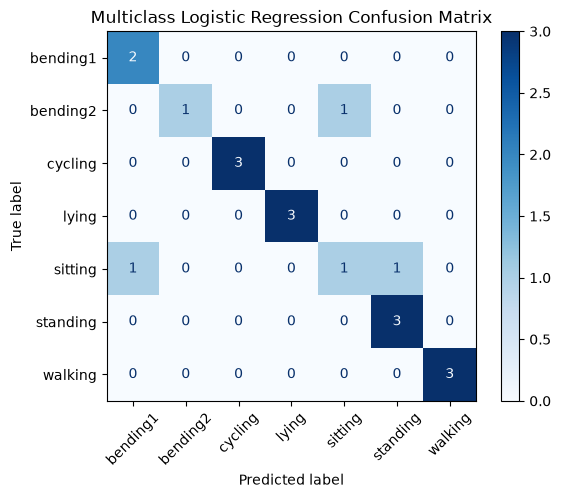

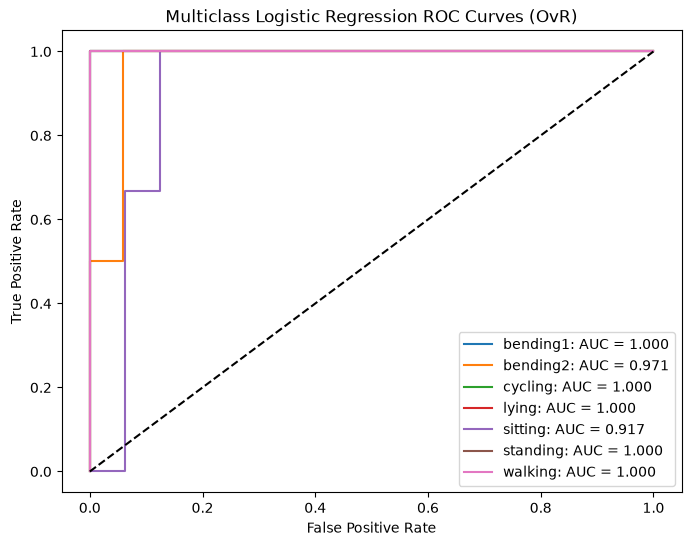

In [13]:
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# Create multiclass labels
activity_labels = {
    activity: i for i, activity in enumerate(activities)
}

y_train_multi = np.array([
    activity_labels[activity]
    for activity, file in train_files
])

y_test_multi = np.array([
    activity_labels[activity]
    for activity, file in test_files
])

# Stratified 4-fold CV for multiclass classification
cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# Cross-validation for l and C
multi_results = []
multi_models = {}

for l in range(1, 21):

    X_l = feature_sets[l]

    pipeline_multi = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            l1_ratio=1.0,
            solver="saga",
            max_iter=10000,
            tol=1e-3,
            random_state=42
        ))
    ])

    grid = GridSearchCV(
        estimator=pipeline_multi,
        param_grid={
            "classifier__C": C_values
        },
        cv=cv_multi,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_l, y_train_multi)

    multi_models[l] = grid.best_estimator_

    multi_results.append({
        "l": l,
        "C": grid.best_params_["classifier__C"],
        "CV Accuracy": grid.best_score_
    })


# Select the best parameters
multi_results_df = pd.DataFrame(multi_results)

multi_results_df = multi_results_df.sort_values(
    ["CV Accuracy", "l", "C"],
    ascending=[False, True, True]
).reset_index(drop=True)

display(multi_results_df.head(10))

best_l_multi = int(multi_results_df.loc[0, "l"])
best_C_multi = float(multi_results_df.loc[0, "C"])
best_cv_multi = multi_results_df.loc[0, "CV Accuracy"]

best_multi_model = multi_models[best_l_multi]


# Extract test features using the selected l
X_test_multi = pd.DataFrame([
    extract_l_features(file, best_l_multi)
    for activity, file in test_files
])

X_test_multi = X_test_multi[
    feature_sets[best_l_multi].columns
]


# Test predictions
y_pred_multi = best_multi_model.predict(X_test_multi)
y_prob_multi = best_multi_model.predict_proba(X_test_multi)

multi_test_accuracy = accuracy_score(
    y_test_multi, y_pred_multi
)

multi_test_error = 1 - multi_test_accuracy

print(f"Best l: {best_l_multi}")
print(f"Best C: {best_C_multi:.6f}")
print(f"CV Accuracy: {best_cv_multi:.4f}")
print(f"Test Accuracy: {multi_test_accuracy:.4f}")
print(f"Test Error: {multi_test_error:.4f}")


# Multiclass confusion matrix
cm_multi = confusion_matrix(
    y_test_multi,
    y_pred_multi,
    labels=np.arange(len(activities))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_multi,
    display_labels=activities
).plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Multiclass Logistic Regression Confusion Matrix")
plt.show()


# One-vs-Rest ROC curves
y_test_bin = label_binarize(
    y_test_multi,
    classes=np.arange(len(activities))
)

plt.figure(figsize=(8, 6))

for i, activity in enumerate(activities):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_prob_multi[:, i]
    )

    auc_i = roc_auc_score(
        y_test_bin[:, i],
        y_prob_multi[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{activity}: AUC = {auc_i:.3f}"
    )

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass Logistic Regression ROC Curves (OvR)")
plt.legend()
plt.show()

Stratified 4-fold cross-validation was used because the smallest
training class (bending2) contained only four instances.

The L1-penalized multinomial logistic regression selected
l = 2 and C = 100, achieving a CV accuracy of 91.42%.

The test accuracy was 84.21%, corresponding to a test error
of 15.79%. Among the 19 test instances, 16 were correctly
classified. Most errors involved sitting and bending2.

The one-vs-rest ROC analysis showed AUC values ranging from
0.917 to 1.000, indicating generally good discrimination.
However, the results should be interpreted cautiously due
to the small test set.

#### ii. Naive Bayes

,Model,l,Parameter,CV Accuracy
0,Gaussian NB,1,1.000000e-07,0.870915
1,Multinomial NB,1,1.000000e-02,0.825163


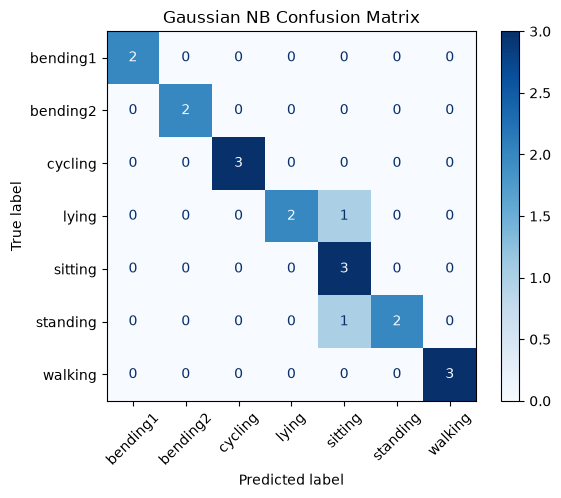

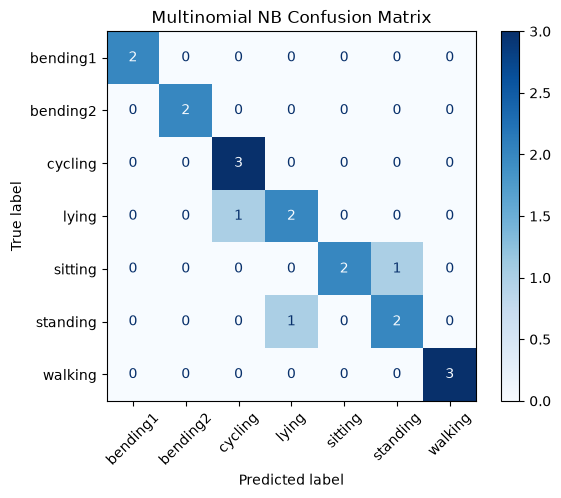

,Model,Best l,CV Accuracy,Test Accuracy,Test Error
0,Gaussian NB,1,0.870915,0.894737,0.105263
1,Multinomial NB,1,0.825163,0.842105,0.157895


In [14]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler

# Candidate parameters
gnb_params = {"classifier__var_smoothing": np.logspace(-12, -6, 7)}
mnb_params = {"classifier__alpha": np.logspace(-3, 2, 11)}

nb_results = []
nb_models = {}

# Cross-validation for Gaussian and Multinomial Naive Bayes
for model_name in ["Gaussian NB", "Multinomial NB"]:

    for l in range(1, 21):

        X_l = feature_sets[l]

        if model_name == "Gaussian NB":
            pipeline_nb = Pipeline([
                ("scaler", StandardScaler()),
                ("classifier", GaussianNB())
            ])
            param_grid = gnb_params

        else:
            pipeline_nb = Pipeline([
                ("scaler", MinMaxScaler()),
                ("classifier", MultinomialNB())
            ])
            param_grid = mnb_params

        grid = GridSearchCV(
            estimator=pipeline_nb,
            param_grid=param_grid,
            scoring="accuracy",
            cv=cv_multi,
            n_jobs=-1
        )

        grid.fit(X_l, y_train_multi)

        nb_models[(model_name, l)] = grid.best_estimator_

        nb_results.append({
            "Model": model_name,
            "l": l,
            "Parameter": list(grid.best_params_.values())[0],
            "CV Accuracy": grid.best_score_
        })


# Select the best model for each Naive Bayes method
nb_results_df = pd.DataFrame(nb_results)

nb_results_df = nb_results_df.sort_values(
    ["Model", "CV Accuracy", "l"],
    ascending=[True, False, True]
)

best_nb_results = (
    nb_results_df.groupby("Model", sort=False)
    .head(1)
    .reset_index(drop=True)
)

display(best_nb_results)


# Evaluate the selected models on the test set
comparison_results = []

for _, row in best_nb_results.iterrows():

    model_name = row["Model"]
    best_l_nb = int(row["l"])

    best_nb_model = nb_models[(model_name, best_l_nb)]

    X_test_nb = pd.DataFrame([
        extract_l_features(file, best_l_nb)
        for activity, file in test_files
    ])

    X_test_nb = X_test_nb[feature_sets[best_l_nb].columns]

    y_pred_nb = best_nb_model.predict(X_test_nb)

    test_acc_nb = accuracy_score(y_test_multi, y_pred_nb)
    test_error_nb = 1 - test_acc_nb

    comparison_results.append({
        "Model": model_name,
        "Best l": best_l_nb,
        "CV Accuracy": row["CV Accuracy"],
        "Test Accuracy": test_acc_nb,
        "Test Error": test_error_nb
    })

    # Confusion matrix
    cm_nb = confusion_matrix(
        y_test_multi,
        y_pred_nb,
        labels=np.arange(len(activities))
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm_nb,
        display_labels=activities
    ).plot(cmap="Blues", xticks_rotation=45)

    plt.title(f"{model_name} Confusion Matrix")
    plt.show()


# Compare the models
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

#### ii. Comparison

Gaussian Naive Bayes achieved a higher cross-validation accuracy (87.09%) than Multinomial Naive Bayes (82.52%).

Gaussian NB also achieved a lower test error (10.53%) compared with Multinomial NB (15.79%). Both models selected l = 1.

Gaussian NB performed better in this experiment, which may be because the extracted time-domain features are continuous measurements. The Gaussian distribution assumption is more appropriate for these features than the multinomial assumption, which is primarily designed for nonnegative count data.

However, the results should be interpreted cautiously due to the small test set.

## 3. ISLR 4.8.3

Assume that observations in class $k$ follow a normal distribution:

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2).
$$

The class-conditional density is

$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

By Bayes' rule, the Bayes classifier assigns an observation to the class maximizing $\pi_k f_k(x)$, where $\pi_k$ is the prior probability of class $k$.

Taking the logarithm and removing constants common to all classes, the discriminant function becomes

$$
\delta_k(x)=
-\frac{1}{2}\log(\sigma_k^2)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
+\log(\pi_k).
$$

Expanding the squared term,

$$
\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac{1}{2}\log(\sigma_k^2)
+\log(\pi_k).
$$

Since the class-specific variances may differ, the coefficient of $x^2$ is generally different across classes.

The decision boundary between classes $k$ and $j$ satisfies

$$
\delta_k(x)-\delta_j(x)=Ax^2+Bx+C=0,
$$

where

$$
A=\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}.
$$

When $\sigma_k^2 \neq \sigma_j^2$, we have $A \neq 0$.

Therefore, the decision boundary is determined by a quadratic equation rather than a linear equation.

**Conclusion:** Since the class-specific variances are not assumed to be equal, the quadratic terms generally do not cancel. Thus, the Bayes classifier under the QDA assumptions has quadratic discriminant functions.

## 4. ISLR 4.8.7

We are given the following class-conditional distributions:

$$
X \mid Y=\text{Yes} \sim N(10,36)
$$

$$
X \mid Y=\text{No} \sim N(0,36)
$$

The prior probabilities are

$$
P(Y=\text{Yes})=0.8, \qquad P(Y=\text{No})=0.2.
$$

Using Bayes' theorem,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}.
$$

Since both classes have variance $\sigma^2=36$, their Gaussian densities at $X=4$ are

$$
f_{\text{Yes}}(4)
=
\frac{1}{\sqrt{72\pi}}
\exp\left(-\frac{(4-10)^2}{72}\right)
=
\frac{1}{\sqrt{72\pi}}e^{-1/2},
$$

and

$$
f_{\text{No}}(4)
=
\frac{1}{\sqrt{72\pi}}
\exp\left(-\frac{(4-0)^2}{72}\right)
=
\frac{1}{\sqrt{72\pi}}e^{-2/9}.
$$

Substituting these densities into Bayes' theorem and canceling the common factor,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8e^{-1/2}}
{0.8e^{-1/2}+0.2e^{-2/9}}
\approx 0.752.
$$

**Conclusion:** The predicted probability that the company will issue a dividend this year is approximately **75.2%**. Since this probability exceeds 0.5, the Bayes classifier predicts **Dividend = Yes**.

## 5.1. Extra Practice ISLR 4.8.4

**(a)** When $p=1$, we consider observations within 10% of the range of $X$ closest to the test observation.

Since $X$ is uniformly distributed on $[0,1]$, the expected fraction of observations used is

$$
P(X \text{ is within the selected interval})=0.1.
$$

Therefore, **10% of the training observations** will be used.

**(b)** When $p=2$, an observation must fall within the selected 10% range for both $X_1$ and $X_2$.

Assuming the observations are uniformly distributed over $[0,1]\times[0,1]$, the expected fraction is

$$
P=0.1\times0.1=0.01.
$$

Therefore, **1% of the training observations** will be used.

**(c)** When $p=100$, an observation must fall within the selected 10% range for all 100 features.

The expected fraction is

$$
P=(0.1)^{100}=10^{-100}.
$$

Therefore, the fraction of training observations used is approximately zero.

**(d)** As the number of features increases, the fraction of observations within a fixed local neighborhood decreases exponentially:

$$
P=(0.1)^p.
$$

Consequently, training observations become increasingly sparse in high-dimensional spaces. KNN must use more distant observations to obtain enough neighbors, making local predictions less reliable.

This illustrates the **curse of dimensionality**, which explains why KNN often performs poorly when $p$ is large.

**(e)** Suppose we construct a $p$-dimensional hypercube with side length $s$ that contains, on average, 10% of the training observations.

Since the observations are uniformly distributed over the unit hypercube,

$$
s^p=0.1.
$$

Solving for $s$,

$$
s=0.1^{1/p}.
$$

For $p=1$:

$$
s=0.1^{1/1}=0.1.
$$

For $p=2$:

$$
s=0.1^{1/2}\approx0.3162.
$$

For $p=100$:

$$
s=0.1^{1/100}\approx0.9772.
$$

Therefore, as the dimensionality increases, the side length required to contain 10% of the observations approaches 1.

In 100 dimensions, the hypercube must cover approximately 97.72% of each feature's range to contain only 10% of the observations.

This demonstrates that neighborhoods become less local in high-dimensional spaces, making KNN less effective.

## 5.2. Extra Practice ISLR 4.8.9

**(a)** Given the odds of defaulting are 0.37, the probability of default is

$$
p=\frac{\text{Odds}}{1+\text{Odds}}
=\frac{0.37}{1+0.37}
=\frac{0.37}{1.37}
\approx0.2701.
$$

Therefore, approximately **27.01%** of individuals with these odds are expected to default.

**(b)** Given the probability of default is 16%, the odds of default are

$$
\text{Odds}
=\frac{p}{1-p}
=\frac{0.16}{1-0.16}
=\frac{0.16}{0.84}
\approx0.1905.
$$

Therefore, the odds of default are approximately **0.1905**, equivalent to **1:5.25** (default to non-default).